# 18 — The C-band counterpart: Sentinel-1 VV/VH dual-pol C2

**Why this module?** The original toolkit's module 18 handles NISAR S-band compact-pol, which is not
acquired over Europe. The operational comparison that matters here is **Sentinel-1 C-band**
(VV/VH, 12-day revisit), which this feasibility study compares with NISAR throughout.

The Sentinel-1 C2 matrix (VV/VH, complex cross term kept) is produced by ESA SNAP from the IW SLC
(graph `s1_c2`: split → orbit → complex calibration → deburst → C2 → multilook 12x3 → terrain
correction to 40 m), then **the same functions** as for NISAR are applied.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nisar_s1.config import load_kit
from nisar_s1 import product as P

kit = load_kit()                                  # training/notebooks/kit_config.yaml
OUT = Path(kit["data_dir"]) / "outputs" / "18"   # outputs stay outside the repository
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
from nisar_s1 import polarimetry as pol
from nisar_s1.snap import dimap_band
from nisar_s1.grid import read_geotiff, polygon_mask
import geopandas as gpd

In [2]:
s1dir = Path(kit["data_dir"]) / "s1"
dims = sorted(s1dir.glob("c2_*.dim"))
print([d.name for d in dims])
def load_c2(dim):
    b = {k: read_geotiff(dimap_band(dim, k)) for k in ("C11", "C12_real", "C12_imag", "C22")}
    c = pol.c2_from_elements(*(np.where(b[k].data == 0, np.nan, b[k].data) for k in ("C11", "C22", "C12_real", "C12_imag")))
    return c, b["C11"]
s1 = {}
for i, (k, d) in enumerate(zip(["pre (21 Jul)", "post (14 Aug)"], dims[:2]), 1):
    c, ref = load_c2(d)
    s1[k] = {"c2": c, "ref": ref, "check": pol.validate_c2(c), **pol.h_alpha_dual(c), "DpRVI": pol.dprvi(c)}
    print(f"[{i}/2] {k}: shape {c.c11.shape}, valid {s1[k]['check']['n_valid']}")
pd.DataFrame({k: v["check"] for k, v in s1.items()}).round(4)

['c2_20260721.dim', 'c2_20260814.dim']
[1/2] pre (21 Jul): shape (172, 175), valid 29670


[2/2] post (14 Aug): shape (173, 175), valid 29792


,pre (21 Jul),post (14 Aug)
n_valid,29670.0000,29792.0000
frac_invalid,0.0143,0.0160
frac_negative_power,0.0000,0.0000
frac_rho_above_1,0.0000,0.0000
frac_negative_det,0.0000,0.0000
max_trace_error,0.0000,0.0000
median_abs_rho,0.1597,0.1603


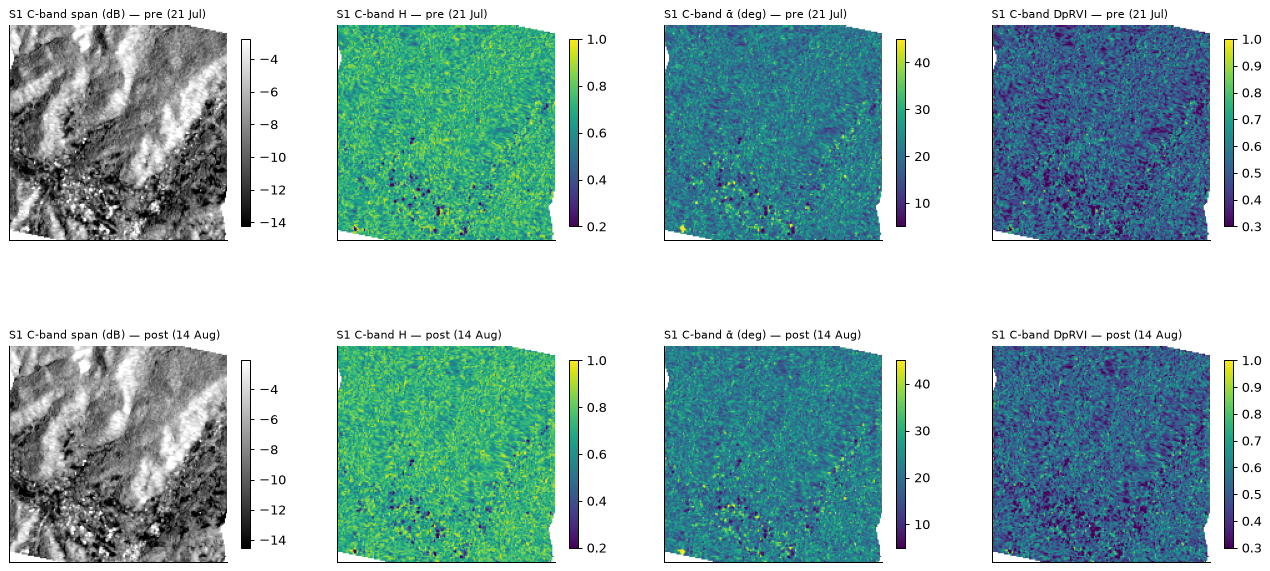

In [3]:
fig, axs = plt.subplots(2, 4, figsize=(18, 8.5))
for row, (k, r) in zip(axs, s1.items()):
    span = pol.to_db(r["c2"].trace)
    for ax, (a, lim, t) in zip(row, [(span, tuple(np.nanpercentile(span, [2, 98])), "span (dB)"), (r["H"], (0.2, 1), "H"),
                                     (r["alpha"], (5, 45), "ᾱ (deg)"), (r["DpRVI"], (0.3, 1), "DpRVI")]):
        im = ax.imshow(a, vmin=lim[0], vmax=lim[1], cmap="gray" if "span" in t else "viridis")
        ax.set_title(f"S1 C-band {t} — {k}", loc="left", fontsize=9); ax.set_xticks([]); ax.set_yticks([]); plt.colorbar(im, ax=ax, shrink=0.7)
fig.savefig(OUT / "18_s1_c2.png", dpi=100, bbox_inches="tight"); plt.show()

## L-band versus C-band over the same forest
At C-band (5.6 cm) the signal comes mostly from the upper canopy (leaves, twigs); at L-band (24 cm)
it penetrates to branches and trunks. Over a closed forest both show high entropy (≈ 0.75); the
clear-cut barely moves H, ᾱ or DpRVI at either band, while the powers drop (notebook 19).

In [4]:
sites = gpd.read_file(kit["aoi"]["site_polygons"]).to_crs(s1["pre (21 Jul)"]["ref"].crs)
rows = []
for k, r in s1.items():
    for _, s in sites.iterrows():
        m = polygon_mask([s.geometry], r["ref"]) & np.isfinite(r["H"])
        rows.append({"date": k, "unit": s.role, "n": int(m.sum()), "H": np.nanmedian(r["H"][m]),
                     "alpha": np.nanmedian(r["alpha"][m]), "DpRVI": np.nanmedian(r["DpRVI"][m]),
                     "VH/VV (dB)": np.nanmedian(pol.to_db(r["c2"].c22[m]) - pol.to_db(r["c2"].c11[m]))})
c_units = pd.DataFrame(rows).round(3); c_units

,date,unit,n,H,alpha,DpRVI,VH/VV (dB)
0,pre (21 Jul),cut,16,0.704,21.518000,0.501,-5.856
1,pre (21 Jul),control,141,0.743,22.193001,0.544,-5.583
2,post (14 Aug),cut,15,0.724,22.087999,0.522,-5.767
3,post (14 Aug),control,144,0.748,23.490999,0.549,-5.252


In [5]:
checks = {
    "two S1 dates": len(s1) == 2,
    "C2 physically valid": all(v['check']['frac_rho_above_1'] == 0 for v in s1.values()),
    "H within [0, 1]": all(np.nanmax(v['H']) <= 1 + 1e-5 for v in s1.values()),
}
for k, v in checks.items():
    print(f"  [{'x' if v else ' '}] {k}")
assert all(checks.values()), "some checks failed: read the messages above"
print("Module 18 STATUS: PASS")

  [x] two S1 dates
  [x] C2 physically valid
  [x] H within [0, 1]
Module 18 STATUS: PASS
